# Montar drive

In [1]:
from google.colab import drive # montar drive
# Acceso a drive (solo en googlecolab)
drive.mount('/content/drive') # genero el acceso a mi google drive para importar los archivos necesarios

Mounted at /content/drive


In [2]:
import os # trabajar con directorios
# creacion de ruta
os.chdir('/content/drive/MyDrive/PFM/')

># Redes neuronales convolucionales

# Paquetes y librerías

In [3]:
!pip install scikit-learn
!pip install scikit-image
!pip install pandas
!pip install tensorflow
!pip install matplotlib
!pip install numpy

In [3]:
# Preparacion del entorno de trabajo para descarga de datos y acceso a carpeta
from pathlib import Path

# essentials
import pandas as pd
import numpy as np

# TensorFlow y Keras
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.models import load_model # cargar modelos

import random

# evaluaciOn de resultados
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix


# Preparación de datos

## Imágenes grayscale

In [4]:
# Directorio
IMG_DIR = Path('Datasets/imagenes_otoscopia')

# Tamaño de reescalado de imagenes
IMG_SIZE = (100, 100)

# Tamaño de los lotes
BATCH_SIZE = 100

In [ ]:
# Directorio
os.getcwd()

'/content/drive/MyDrive/PFM'

In [23]:
# Carga de imagenes train
train_ds = tf.keras.utils.image_dataset_from_directory(
    IMG_DIR / "train",
    labels="inferred", # infiere las etiquetas de las carpetas
    label_mode="int", # etiquetas como enteros
    color_mode="grayscale",   # 1 canal
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Carga de imagenes val
val_ds = tf.keras.utils.image_dataset_from_directory(
    IMG_DIR / "val",
    labels="inferred",
    label_mode="int",
    color_mode="grayscale",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

#Cargar imágenes de test
test_ds = tf.keras.utils.image_dataset_from_directory(
    IMG_DIR / "test",
    labels="inferred",
    label_mode="int",
    color_mode="grayscale",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

print("Clases:", train_ds.class_names)

Found 840 files belonging to 2 classes.
Found 180 files belonging to 2 classes.
Found 180 files belonging to 2 classes.
Clases: ['Myringosclerosis', 'Normal']


In [ ]:
label_map = {i: name for i, name in enumerate(train_ds.class_names)}
print(label_map)

{0: 'Myringosclerosis', 1: 'Normal'}


In [ ]:
# Comprobacion de las dimensiones
for xb, yb in train_ds.take(1):
    print("Batch imágenes:", xb.shape)   # (B, H, W, 1)
    print("Batch labels:", yb.shape)


Batch imágenes: (100, 100, 100, 1)
Batch labels: (100,)


## Imágenes RGB

Para la RESNET50.

In [6]:
# Carga de imagenes train
rgb_train_ds = tf.keras.utils.image_dataset_from_directory(
    IMG_DIR / "train",
    labels="inferred", # infiere las etiquetas de las carpetas
    label_mode="int", # etiquetas como enteros
    color_mode="rgb",   # 3 canal
    image_size=(100,100),
    batch_size=BATCH_SIZE
)

# Carga de imagenes val
rgb_val_ds = tf.keras.utils.image_dataset_from_directory(
    IMG_DIR / "val",
    labels="inferred",
    label_mode="int",
    color_mode="rgb",
    image_size=(100,100),
    batch_size=BATCH_SIZE
)

#Cargar imágenes de test
rgb_test_ds = tf.keras.utils.image_dataset_from_directory(
    IMG_DIR / "test",
    labels="inferred",
    label_mode="int",
    color_mode="rgb",
    image_size=(100,100),
    batch_size=BATCH_SIZE
)

print("Clases:", rgb_train_ds.class_names)

Found 840 files belonging to 2 classes.
Found 180 files belonging to 2 classes.
Found 180 files belonging to 2 classes.
Clases: ['Myringosclerosis', 'Normal']


In [7]:
# Comprobacion de las dimensiones
for xb, yb in rgb_train_ds.take(1):
    print("Batch imágenes:", xb.shape)   # (B, H, W, 1)
    print("Batch labels:", yb.shape)


Batch imágenes: (100, 100, 100, 3)
Batch labels: (100,)


Para la RESNET50 decido dejar las imágenes en su tamaño original.

## Visualizar imágenes

In [25]:
def visualizar_img(dataset, class_names, n=9):
    plt.figure(figsize=(8, 8))
    for images, labels in dataset.take(1):   # toma un batch del dataset
        for i in range(n):
            ax = plt.subplot(3, 3, i+1)
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.title(class_names[labels[i]])
            plt.axis("off")
    plt.tight_layout()
    plt.show()

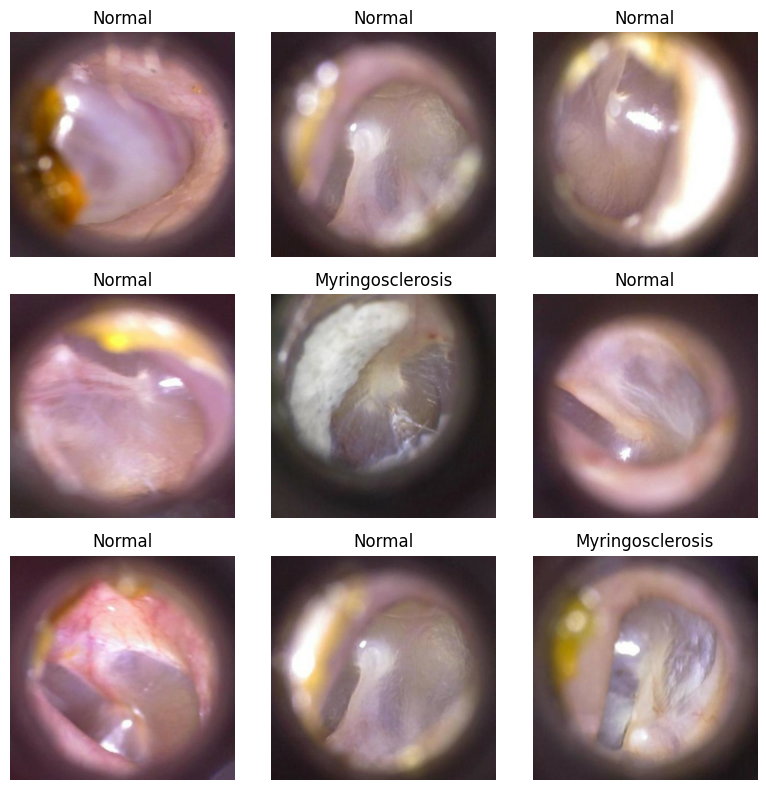

In [ ]:
# Train RGB
class_names = rgb_train_ds.class_names
visualizar_img(rgb_train_ds, class_names)

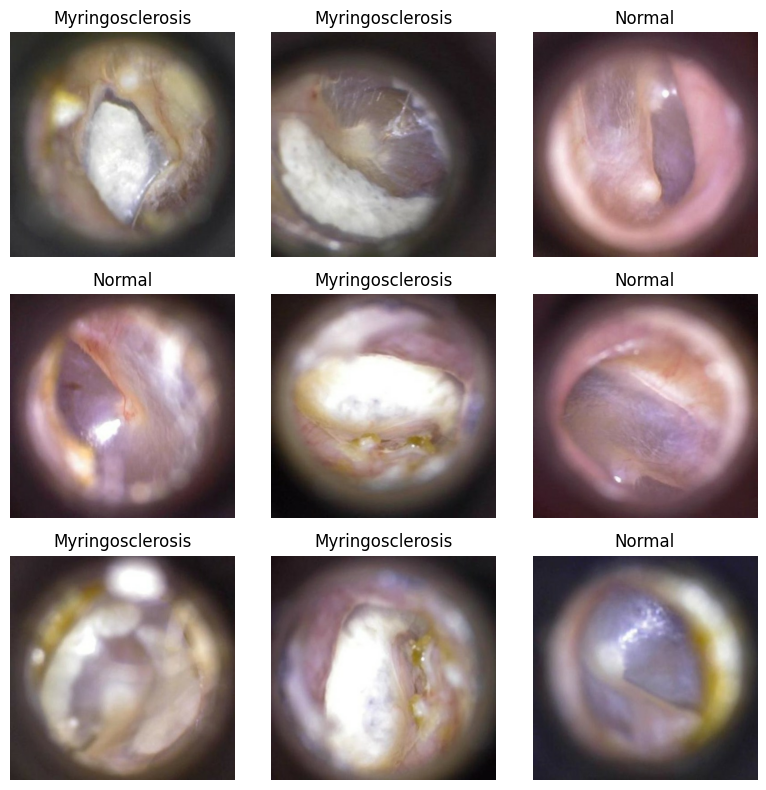

In [ ]:
class_names = rgb_val_ds.class_names
visualizar_img(rgb_val_ds, class_names)

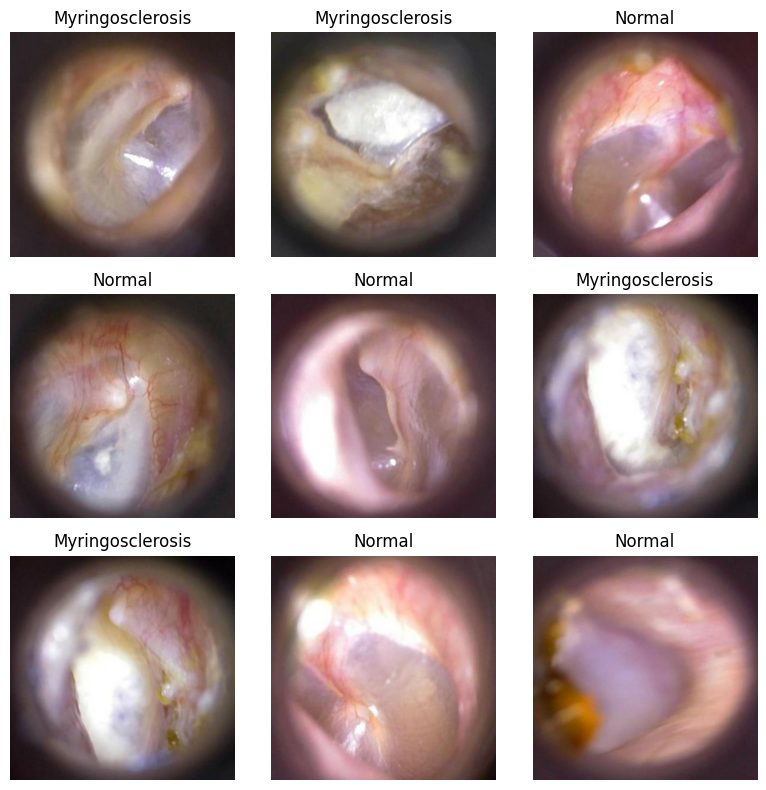

In [ ]:
class_names = rgb_test_ds.class_names
visualizar_img(rgb_test_ds, class_names)

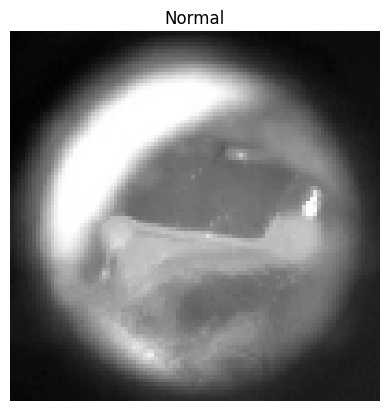

In [37]:
images, labels = next(iter(train_ds))
plt.imshow(images[0].numpy().squeeze().astype("uint8"), cmap="gray")
plt.title(class_names[labels[0]])
plt.axis("off")
plt.show()

# Definición de funciones

## Definir función para compilar y entrenar los modelos

In [8]:
def configurar_y_entrenar(x, es_pat, mc_dir, e, train_dataset, val_dataset):

    # Early stopping
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        min_delta=0,
        patience=es_pat,
        mode='auto',
        baseline=None,
        restore_best_weights=True, # restaurar los pesos del modelo a los de la mejor epoch
        start_from_epoch=0
    )

    # model checkpoint
    model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath = mc_dir,
        monitor='val_loss',
        save_best_only=True, # guardar solo el mejor
        save_weights_only=False, # guarda el modelo completo, no solo los pesos
        mode='auto',
        save_freq='epoch'
    )

    # Configuración del proceso de aprendizaje
    x.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

    # Entrenamiento
    history = x.fit(train_dataset,
                    epochs=e,
                    batch_size = BATCH_SIZE, # Use the defined BATCH_SIZE
                    validation_data=val_dataset,
                    callbacks=[early_stopping, model_checkpoint])

    return x, history, early_stopping

## Función para visualizar los resultados

In [9]:
def resumen(model, hist_df, earlystop):

  # Epochs entrenadas
  epochs_entrenadas = len(hist_df)

  # Mejor epoch según val_loss
  best_epoch = hist_df['val_loss'].idxmin()   # indice de la fila
  best_metrics = hist_df.loc[best_epoch]

  resumen = (
        f"Resumen entrenamiento\n"
        f"Epochs entrenadas: {epochs_entrenadas}\n"
        f"Mejor epoch (según val_loss): {best_epoch}\n"
        f"{best_metrics}\n"
        f"Epoch de parada (early stopping): {earlystop['0'].iloc[0] if isinstance(earlystop, pd.DataFrame) else earlystop.stopped_epoch}"
  )

  return resumen

## Visualizar pérdida en entrenamiento y validación

In [10]:
# Gráfica  loss y val_loss

def visualizar_loss(hist_df):
  plt.plot(hist_df['loss'], label='loss')
  plt.plot(hist_df['val_loss'], label = 'val_loss')
  plt.xlabel('Epoch')
  plt.ylabel('loss')
  plt.legend(loc='lower right')
  plt.yscale('log') # escala logarítmica
  plt.show()

# Modelos

## Modelo 1

In [ ]:
model1 = Sequential()

# Primer capa Conv2D:
model1.add(Conv2D(32, (7, 7), activation="sigmoid", input_shape=(100, 100, 1)))
model1.add(MaxPooling2D(2, 2))

# Segunda capa Conv2D:
model1.add(Conv2D(64, (5, 5), activation="relu"))
model1.add(MaxPooling2D(2, 2))

# Tercera capa Conv2D:
model1.add(Conv2D(128, (3, 3), activation="relu"))
model1.add(MaxPooling2D(2, 2))

# Desenlace
model1.add(Flatten())
model1.add(Dense(512, activation='relu')) # MIRAR
model1.add(Dense(1, activation='sigmoid'))

model1.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 94, 94, 32)     │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 43, 43, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 21, 21, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 19, 19, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │     5,308,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,436,161 (20.74 MB)

 Trainable params: 5,436,161 (20.74 MB)

 Non-trainable params: 0 (0.00 B)

### Configuración y entrenamiento

In [ ]:
# Directorio donde guardar el mejor modelo
model1_dir = "Modelos/ccn.otoscopia.model1.keras"

# Configuración y entrenamiento del modelo
model1_com, history1, earlystop1 = configurar_y_entrenar(model1,10,model1_dir,100,train_ds,val_ds)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 194ms/step - accuracy: 0.4923 - loss: 1.8619 - val_accuracy: 0.5000 - val_loss: 0.6950
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 133ms/step - accuracy: 0.5275 - loss: 0.6919 - val_accuracy: 0.5000 - val_loss: 0.7248
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 169ms/step - accuracy: 0.4880 - loss: 0.7101 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - accuracy: 0.5158 - loss: 0.6942 - val_accuracy: 0.5000 - val_loss: 0.6946
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step - accuracy: 0.4860 - loss: 0.6963 - val_accuracy: 0.5000 - val_loss: 0.6933
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step - accuracy: 0.4958 - loss: 0.6935 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 164ms/step - accuracy: 0.4937 - loss: 0.6934 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step - accuracy: 0.4936 - loss: 0.6933 - val_accuracy: 0.5000 - v

In [ ]:
  # guardar history
  pd.DataFrame(history1.history).to_csv("Modelos/cnn.history1.csv", index=False)

  # guardar earlystop
  pd.DataFrame([earlystop1.stopped_epoch]).to_csv("Modelos/cnn.earlystop1.csv", index=False)

### Evaluación del modelo

In [ ]:
# Cargar modelo guardado si fuera necesario
model1_com = keras.models.load_model("Modelos/ccn.otoscopia.model1.keras")
# importar history csv
history1 = pd.read_csv("Modelos/cnn.history1.csv")
# importar earlystop
earlystop1 = pd.read_csv("Modelos/cnn.earlystop1.csv")

In [ ]:
print(resumen(model1_com, history1,earlystop1))

Resumen entrenamiento
Epochs entrenadas: 58
Mejor epoch (según val_loss): 47
accuracy        0.966667
loss            0.103987
val_accuracy    0.938889
val_loss        0.200919
Name: 47, dtype: float64
Epoch de parada (early stopping): 57


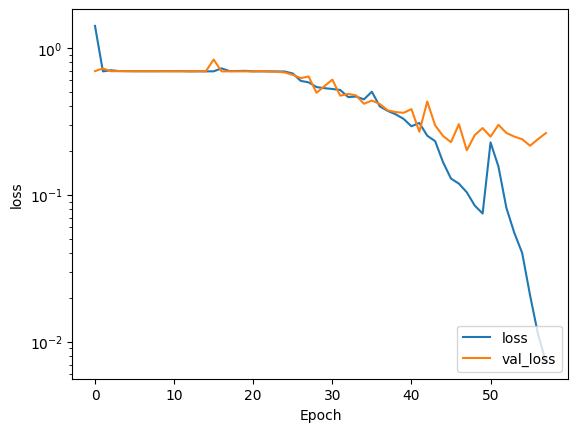

In [ ]:
visualizar_loss(history1)

## Modelo 2

### Configuración

In [ ]:
model2 = Sequential()

# Primer capa Conv2D:
model2.add(Conv2D(32, (7, 7), activation="sigmoid", input_shape=(100, 100, 1)))
model2.add(MaxPooling2D(2, 2))

# Segunda capa Conv2D:
model2.add(Conv2D(64, (5, 5), activation="sigmoid"))
model2.add(MaxPooling2D(2, 2))

# Segunda capa Conv2D:
model2.add(Conv2D(128, (5, 5), activation="sigmoid"))
model2.add(MaxPooling2D(2, 2))

model2.add(Flatten())
model2.add(Dense(1, activation='sigmoid'))

model2.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 94, 94, 32)     │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 43, 43, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 21, 21, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 17, 17, 128)    │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │         8,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 265,985 (1.01 MB)

 Trainable params: 265,985 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

### Compilación y entrenamiento

In [ ]:
# Directorio donde guardar el mejor modelo
model2_dir = "Modelos/ccn.otoscopia.model2.keras"

# Configuración y entrenamiento del modelo
model2_com, history2, earlystop2 = configurar_y_entrenar(model2,10,model2_dir,100,train_ds,val_ds)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 151ms/step - accuracy: 0.4945 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 121ms/step - accuracy: 0.5051 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 126ms/step - accuracy: 0.4976 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 125ms/step - accuracy: 0.4854 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step - accuracy: 0.5160 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 119ms/step - accuracy: 0.5025 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 120ms/step - accuracy: 0.4943 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - accuracy: 0.4871 - loss: 0.6932 - val_accuracy: 0.5000 - v

In [ ]:
  # guardar history
  pd.DataFrame(history2.history).to_csv("Modelos/cnn.history2.csv", index=False)
  # guardar earlystop
  pd.DataFrame([earlystop2.stopped_epoch]).to_csv("Modelos/cnn.earlystop2.csv", index=False)

### Evaluación

In [ ]:
# Cargar modelo guardado si fuera necesario
model2_com = keras.models.load_model("Modelos/ccn.otoscopia.model2.keras")
# importar history csv
history2 = pd.read_csv("Modelos/cnn.history2.csv")
# importar earlystop
earlystop2 = pd.read_csv("Modelos/cnn.earlystop2.csv")

In [ ]:
print(resumen(model2_com, history2,earlystop2))

Resumen entrenamiento
Epochs entrenadas: 11
Mejor epoch (según val_loss): 0
accuracy        0.483333
loss            0.693162
val_accuracy    0.500000
val_loss        0.693147
Name: 0, dtype: float64
Epoch de parada (early stopping): 10


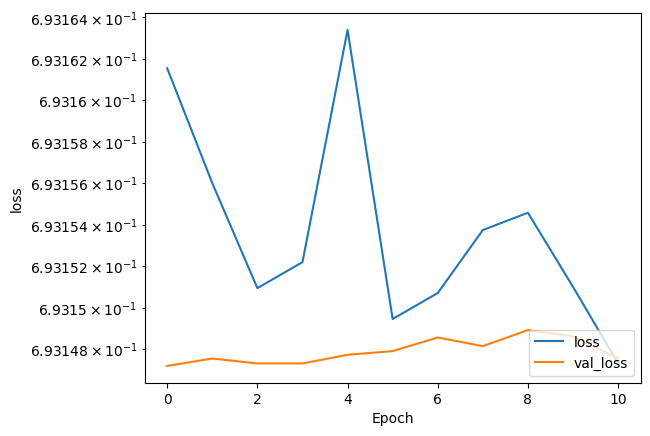

In [ ]:
visualizar_loss(history2)

## Modelo RestNet50

### Configuración del modelo

In [11]:
resnet50 = tf.keras.applications.ResNet50(
    include_top=False, # quitar capas densas
    input_shape=(100,100,3),
    pooling='max',
    weights='imagenet' # imagenes RGB
)

for layer in resnet50.layers:
    layer.trainable=False # capas no entrenables

modelRN50 = tf.keras.models.Sequential()
modelRN50.add(resnet50)
modelRN50.add(Flatten())
modelRN50.add(Dense(512, activation='relu'))
modelRN50.add(Dense(1, activation='sigmoid'))

modelRN50.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,637,313 (93.98 MB)

 Trainable params: 1,049,601 (4.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

### Entrenamiento

In [12]:
# Directorio donde guardar el mejor modelo
modelRN50_dir = "Modelos/ccn.otoscopia.RN50.keras"

# Configuración y entrenamiento del modelo
modelRN50_com, historyRN50, earlystopRN50 = configurar_y_entrenar(modelRN50,5,modelRN50_dir,10, rgb_train_ds, rgb_val_ds)

Epoch 1/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 56s 5s/step - accuracy: 0.5140 - loss: 8.8227 - val_accuracy: 0.6333 - val_loss: 1.4974
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 264ms/step - accuracy: 0.7143 - loss: 1.1509 - val_accuracy: 0.8833 - val_loss: 0.3387
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 146ms/step - accuracy: 0.8507 - loss: 0.4438 - val_accuracy: 0.8056 - val_loss: 0.5547
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 255ms/step - accuracy: 0.8772 - loss: 0.3310 - val_accuracy: 0.9111 - val_loss: 0.2494
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step - accuracy: 0.9106 - loss: 0.2086 - val_accuracy: 0.9000 - val_loss: 0.2538
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 264ms/step - accuracy: 0.9369 - loss: 0.1436 - val_accuracy: 0.9500 - val_loss: 0.1870
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 258ms/step - accuracy: 0.9805 - loss: 0.0822 - val_accuracy: 0.9611 - val_loss: 0.1445
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 259ms/step - accuracy: 0.9843 - loss: 0.0658 - val_accuracy: 0.9500 - val_loss: 0

In [13]:
# guardar history como data.frame
pd.DataFrame(historyRN50.history).to_csv("Modelos/cnn.historyRN50.csv", index=False)
# guardar earlystop como data.frame
pd.DataFrame([earlystopRN50.stopped_epoch]).to_csv("Modelos/cnn.earlystopRN50.csv", index=False)

### Evaluación del modelo

In [14]:
# Cargar modelo guardado si fuera necesario
modelRN50_com = keras.models.load_model("Modelos/ccn.otoscopia.RN50.keras")
# importar history csv
historyRN50 = pd.read_csv("Modelos/cnn.historyRN50.csv")
# importar earlystop
earlystopRN50 = pd.read_csv("Modelos/cnn.earlystopRN50.csv")

In [15]:
print(resumen(modelRN50_com, historyRN50,earlystopRN50))

Resumen entrenamiento
Epochs entrenadas: 10
Mejor epoch (según val_loss): 8
accuracy        0.989286
loss            0.054521
val_accuracy    0.972222
val_loss        0.127435
Name: 8, dtype: float64
Epoch de parada (early stopping): 0


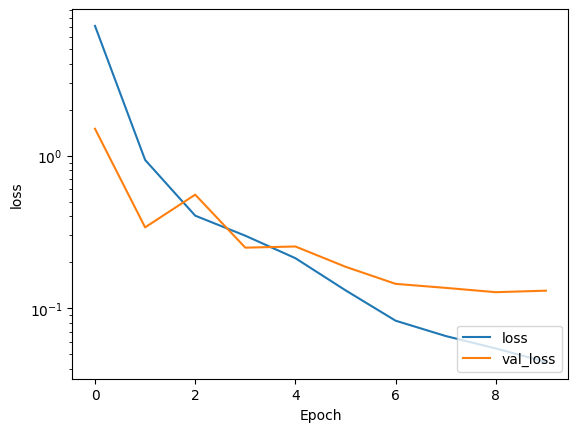

In [16]:
visualizar_loss(historyRN50)

#### resnet50 B

In [17]:
# Directorio donde guardar el mejor modelo
modelRN50B_dir = "Modelos/ccn.otoscopia.RN50B.keras"

# Configuración y entrenamiento del modelo
modelRN50B_com, historyRN50B, earlystopRN50B = configurar_y_entrenar(modelRN50,5,modelRN50B_dir,20, rgb_train_ds, rgb_val_ds)

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - accuracy: 0.8755 - loss: 0.5744 - val_accuracy: 0.8056 - val_loss: 0.7192
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 292ms/step - accuracy: 0.9235 - loss: 0.1922 - val_accuracy: 0.9167 - val_loss: 0.2566
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 298ms/step - accuracy: 0.9621 - loss: 0.0859 - val_accuracy: 0.9778 - val_loss: 0.1203
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 266ms/step - accuracy: 0.9915 - loss: 0.0325 - val_accuracy: 0.9722 - val_loss: 0.0977
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 136ms/step - accuracy: 0.9944 - loss: 0.0273 - val_accuracy: 0.9778 - val_loss: 0.1071
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 135ms/step - accuracy: 0.9970 - loss: 0.0228 - val_accuracy: 0.9778 - val_loss: 0.1095
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 256ms/step - accuracy: 0.9995 - loss: 0.0143 - val_accuracy: 0.9778 - val_loss: 0.0836
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step - accuracy: 0.9995 - loss: 0.0108 - val_accuracy: 0.9778 - val_loss: 0

In [18]:
# guardar history como data.frame
pd.DataFrame(historyRN50B.history).to_csv("Modelos/cnn.historyRN50B.csv", index=False)
# guardar earlystop como data.frame
pd.DataFrame([earlystopRN50B.stopped_epoch]).to_csv("Modelos/cnn.earlystopRN50B.csv", index=False)

In [19]:
# Cargar modelo guardado si fuera necesario
modelRN50B_com = keras.models.load_model("Modelos/ccn.otoscopia.RN50B.keras")
# importar history csv
historyRN50B = pd.read_csv("Modelos/cnn.historyRN50B.csv")
# importar earlystop
earlystopRN50B = pd.read_csv("Modelos/cnn.earlystopRN50B.csv")

In [20]:
print(resumen(modelRN50B_com, historyRN50B,earlystopRN50B))

Resumen entrenamiento
Epochs entrenadas: 20
Mejor epoch (según val_loss): 14
accuracy        1.000000
loss            0.004662
val_accuracy    0.977778
val_loss        0.076764
Name: 14, dtype: float64
Epoch de parada (early stopping): 19


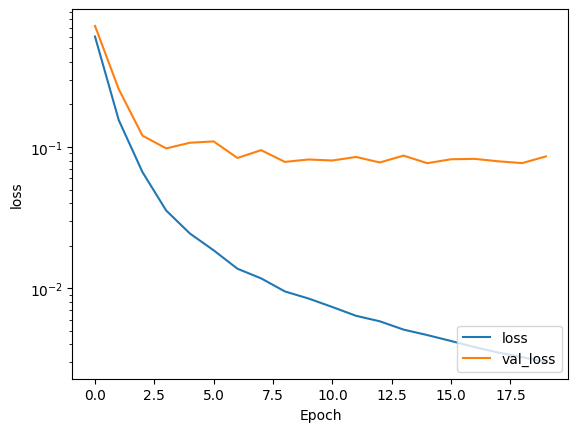

In [21]:
visualizar_loss(historyRN50B)

# Test

In [ ]:
# Evaluar en test
test_loss_rn50, test_acc_rn50 = modelRN50_com.evaluate(rgb_test_ds)
print(f"Loss en test (modelRN50): {test_loss_rn50:.4f}")
print(f"Accuracy en test (modelRN50): {test_acc_rn50:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 21s 11s/step - accuracy: 0.9248 - loss: 0.1699
Loss en test (modelRN50): 0.1764
Accuracy en test (modelRN50): 0.9222


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step 
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step


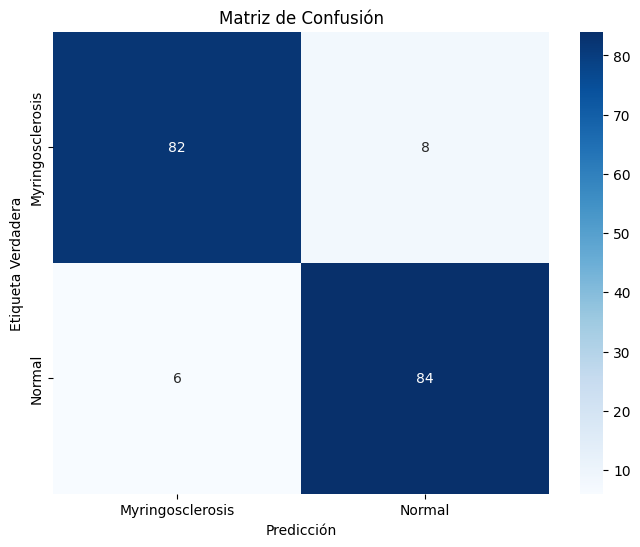

In [ ]:
import seaborn as sns

def visualizar_confusion_matrix(model, dataset, class_names):
    """
    Calcula y visualiza la matriz de confusión para un modelo dado en un dataset.

    Args:
        model (tf.keras.Model): El modelo entrenado.
        dataset (tf.data.Dataset): El dataset de evaluación.
        class_names (list): Lista de nombres de las clases.
    """
    # Obtener las etiquetas verdaderas y las predicciones
    y_true = []
    y_pred = []
    for images, labels in dataset:
        y_true.extend(labels.numpy())
        predictions = model.predict(images)
        # Para modelos con salida sigmoide (clasificación binaria)
        y_pred.extend((predictions > 0.5).astype("int").flatten())

    # Calcular la matriz de confusión
    cm = confusion_matrix(y_true, y_pred)

    # Visualizar la matriz de confusión
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicción')
    plt.ylabel('Etiqueta Verdadera')
    plt.title('Matriz de Confusión')
    plt.show()

# Matriz de confusión en test para modelRN50
class_names_rn50 = rgb_test_ds.class_names # Obtener nombres de clases del dataset
visualizar_confusion_matrix(modelRN50_com, rgb_test_ds, class_names_rn50)

In [ ]:
y_true = []
y_pred = []
for images, labels in rgb_test_ds:
    y_true.extend(labels.numpy())
    predictions = modelRN50_com.predict(images)
    y_pred.extend((predictions > 0.5).astype("int").flatten())

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step 
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step


In [ ]:
def mostrar_predicciones(model, dataset, class_names, n):
    # Obtener un batch
    images, labels = next(iter(dataset))
    labels = labels.numpy() # Get true labels as numpy array

    # Predicciones
    predictions = model.predict(images)
    # Convert probabilities to binary predictions (0 or 1)
    preds = (predictions > 0.5).astype("int").flatten()


    plt.figure(figsize=(12, 6))
    for i in range(n):
        ax = plt.subplot(1, n, i+1)
        # Ensure images have 3 channels for display if they are grayscale
        if images[i].shape[-1] == 1:
            display_image = tf.image.grayscale_to_rgb(images[i])
        else:
            display_image = images[i]

        plt.imshow(display_image.numpy().astype("uint8"))

        # Check if prediction is correct
        color = "green" if preds[i] == labels[i] else "red"

        plt.title(f"Pred: {class_names[preds[i]]}\nTrue: {class_names[labels[i]]}",
                  color=color, fontsize=10)
        plt.axis("off")
    plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step 


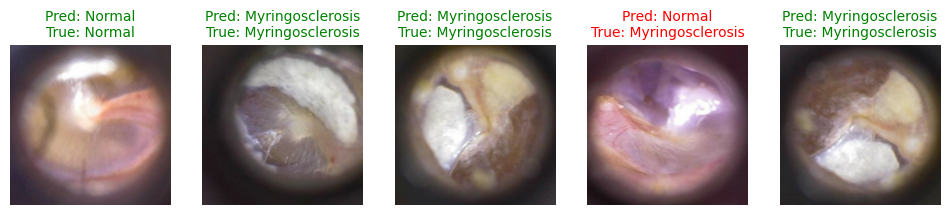

In [ ]:
mostrar_predicciones(modelRN50_com, rgb_test_ds, class_names_rn50, n=5)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step 


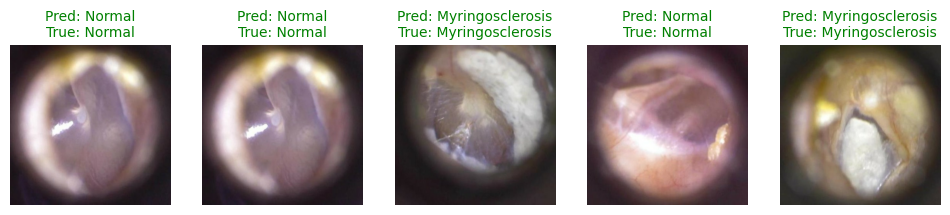

In [ ]:
mostrar_predicciones(modelRN50B_com, rgb_test_ds, class_names_rn50B, n=5)